# Tilt-series alignment from an MRC stack

Makes `phi_astra.npy`, `theta_astra.npy`, `psi_astra.npy` and `translation_astra.npy` for `general_interface_ptychotomo_Te.py`.

It uses the same calculations and settings as the repo's `Alignment_Te.py` and `scatterem/solvers.py`, copied into this notebook, so the repo isn't needed. The one difference is the TV smoothing: the repo calls the external `ccpi` package, and here a PyTorch version of the same method (FGP-TV) is used instead.

Edit the settings cell, then run top to bottom.

In [4]:
# ---------------- settings ----------------
from pathlib import Path

MRC_STACK  = Path('/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/stacks/ptycho_tilt.mrc')        # one summed-phase frame per tilt
OUTPUT_DIR = Path('/dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/stacks/alignment_output')

TILT_ANGLES_DEG = [-70, -68, -64, -60, -56, -52, -48, -44, -40, -36, -32, -28, -24, -20, -16, -12, -8, -4,
                  0, 4, 8, 12, 16, 20, 24, 28, 32, 36, 40, 44, 48, 52, 56, 60, 64, 68, 72]

PIXEL_A = None     # pixel size of the frames in Å; None = read from the MRC header
K_MAX = 1.0        # 1/Å, the k_max of the end-to-end script (its voxel size is dx = 1 / (2 * k_max))

CROP_SIZE = None   # cut a square of this many pixels from the middle of each frame first; None = no crop
BIN = 8            # then downsample by this factor. Aim for frames of about 200-250 pixels after binning
TILTS_PER_CHUNK = 4  # tilts processed together on the GPU; lower it if you run out of memory
INVERT = False     # set True if the particle is darker than the background
DEVICE = 'cuda:0'

## 1. Load the stack

37 frames of 1571 x 1571 pixels, 0.0000 Å per pixel


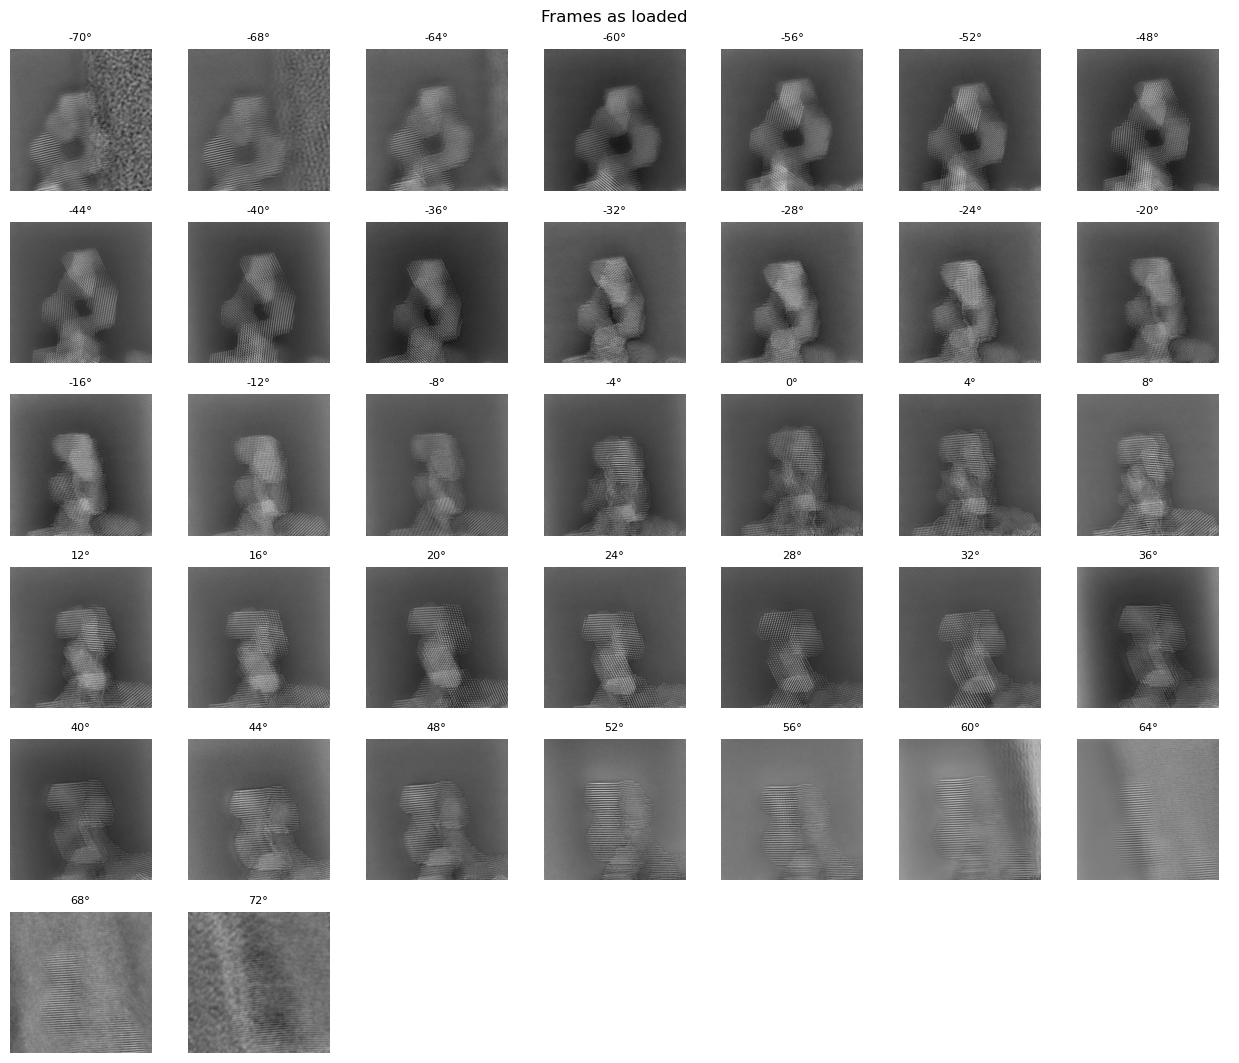

In [5]:
import numpy as np
import torch as th
import torch.nn.functional as F
import matplotlib.pyplot as plt
import mrcfile
from tqdm.auto import tqdm

device = th.device(DEVICE)

with mrcfile.open(MRC_STACK, permissive=True) as m:
    stack = np.asarray(m.data, dtype=np.float64)
    pixel_A = PIXEL_A or float(m.voxel_size.x)

angles = np.asarray(TILT_ANGLES_DEG, dtype=float)
assert len(angles) == len(stack), f'{len(stack)} frames but {len(angles)} angles'
print(f'{len(stack)} frames of {stack.shape[1]} x {stack.shape[2]} pixels, {pixel_A:.4f} Å per pixel')

def show(imgs, title, vline=False):
    n = len(imgs); c = int(np.ceil(np.sqrt(n))); r = int(np.ceil(n / c))
    fig, axs = plt.subplots(r, c, figsize=(1.8 * c, 1.8 * r), squeeze=False)
    for i, ax in enumerate(axs.flat):
        ax.axis('off')
        if i < n:
            ax.imshow(imgs[i], cmap='gray'); ax.set_title(f'{angles[i]:.0f}°', fontsize=8)
            if vline:
                ax.axvline((imgs.shape[-1] - 1) / 2, color='r', lw=0.6)
    fig.suptitle(title); plt.tight_layout(); plt.show()

show(stack, 'Frames as loaded')

## 2. Prepare the frames

Crop a square from the middle of each frame, bin, set the background to zero, and give every frame the same total signal. The scaling at the end keeps the solver's step size small compared with the volume values.

In [6]:
size = min(CROP_SIZE or min(stack.shape[1:]), min(stack.shape[1:]))
S = (size // BIN) * BIN
r0, c0 = (stack.shape[1] - S) // 2, (stack.shape[2] - S) // 2
imgs = stack[:, r0:r0 + S, c0:c0 + S].reshape(len(stack), S // BIN, BIN, S // BIN, BIN).mean((2, 4))
imgs = -imgs if INVERT else imgs
imgs = np.clip(imgs - np.percentile(imgs, 5, axis=(1, 2), keepdims=True), 0, None)
imgs = imgs * (imgs.sum((1, 2)).mean() / imgs.sum((1, 2)))[:, None, None]
N = imgs.shape[-1]
imgs = imgs * (0.5 * N / imgs.max())
pixel_binned = pixel_A * BIN
print(f'{N} x {N} pixels at {pixel_binned:.4f} Å per pixel')
print(f'rough GPU memory needed: {(min(TILTS_PER_CHUNK, len(imgs)) * 32 + 48) * N**3 / 1e9:.1f} GB')

196 x 196 pixels at 0.0000 Å per pixel
rough GPU memory needed: 1.3 GB


## 3. Make the tilt axis vertical

The solver assumes the tilt axis runs straight up and down. Adding each frame up along its rows gives a profile along the axis that should be the same at every tilt, so the rotation where those profiles agree best is the one that makes the axis vertical. In the result, features should move left and right through the series, not up and down.

rotating frames by -17.1°


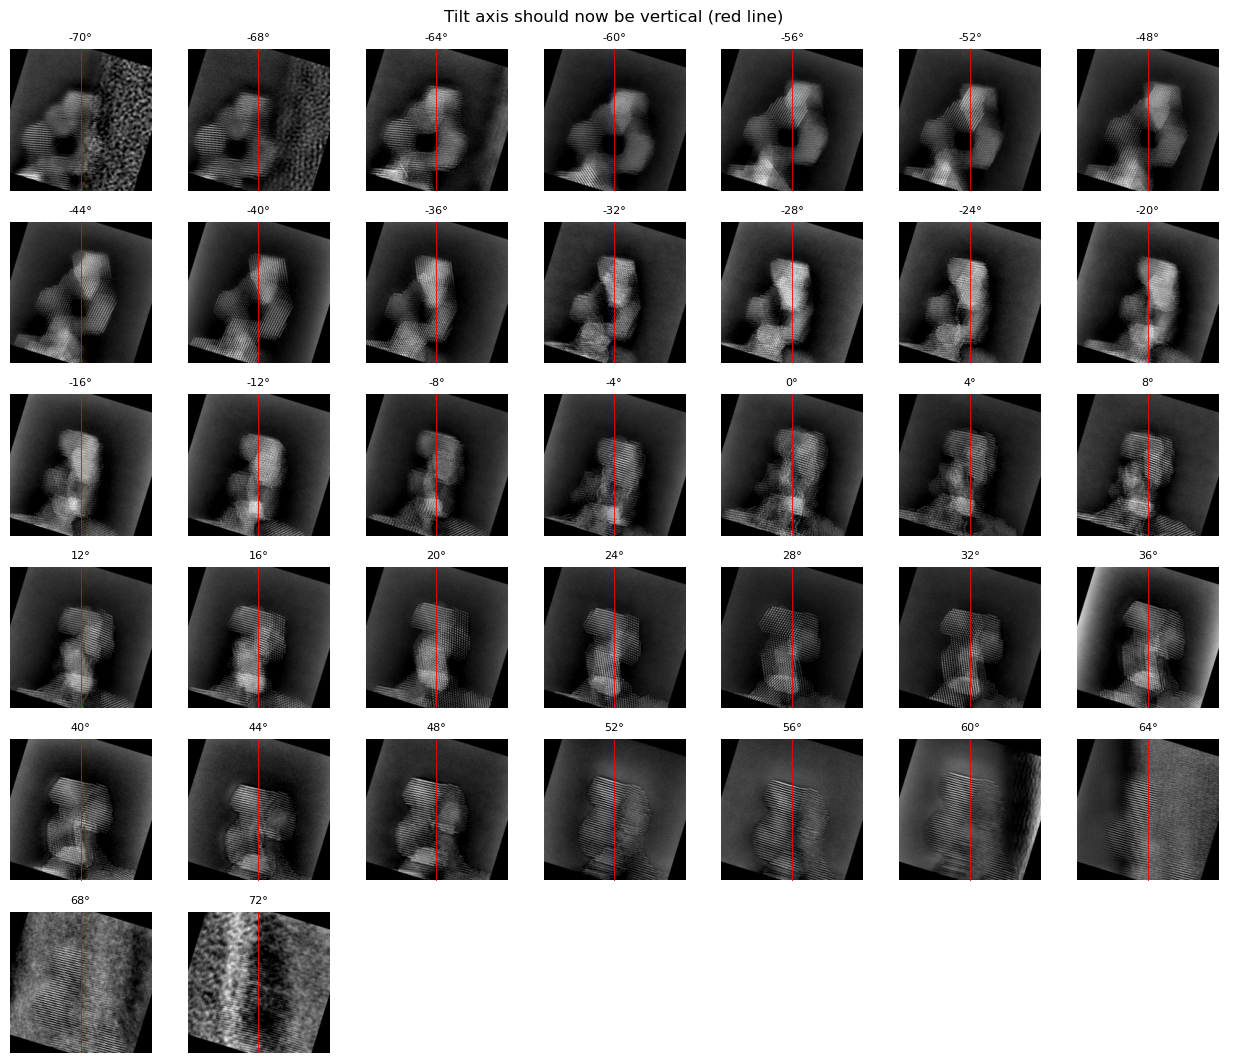

In [7]:
def rotate(imgs, deg):
    a = np.deg2rad(deg)
    A = th.tensor([[np.cos(a), -np.sin(a), 0], [np.sin(a), np.cos(a), 0]], dtype=th.float32)
    x = th.as_tensor(imgs, dtype=th.float32)[:, None]
    grid = F.affine_grid(A.expand(len(x), 2, 3), list(x.shape), align_corners=False)
    return F.grid_sample(x, grid, align_corners=False)[:, 0].numpy()

def mismatch(deg):
    p = rotate(imgs, deg).sum(2)
    p = p / p.sum(1, keepdims=True)
    com = (p * np.arange(N)).sum(1)                       # remove drift along the axis
    k = np.fft.fftfreq(N)
    p = np.fft.ifft(np.fft.fft(p, axis=1) * np.exp(2j * np.pi * k * (com[:, None] - (N - 1) / 2)), axis=1).real
    return p.std(0).sum() / p.mean(0).sum()

trial = np.arange(-90, 90, 1.0)
axis_deg = trial[np.argmin([mismatch(a) for a in trial])]
fine = np.arange(axis_deg - 1, axis_deg + 1.01, 0.1)
axis_deg = float(fine[np.argmin([mismatch(a) for a in fine])])
print(f'rotating frames by {axis_deg:.1f}°')
imgs_rot = rotate(imgs, axis_deg)
show(imgs_rot, 'Tilt axis should now be vertical (red line)', vline=True)

## 4. The alignment solver

Copied from `scatterem/solvers.py`, with the same maths and default values. Only `tv_smooth` is new: it replaces `ccpi`'s `FGP_TV`.

In [8]:
def rotation_matrix(phi, theta, psi):
    # Rz(phi) @ Ry(theta) @ Rx(psi), batched (as affine_matrix_3D_ZYX)
    c1, s1, c2, s2, c3, s3 = th.cos(phi), th.sin(phi), th.cos(theta), th.sin(theta), th.cos(psi), th.sin(psi)
    z = th.zeros_like(phi)
    return th.stack([th.stack([c1*c2, c1*s2*s3 - c3*s1, s1*s3 + c1*c3*s2, z], 1),
                     th.stack([c2*s1, c1*c3 + s1*s2*s3, c3*s1*s2 - c1*s3, z], 1),
                     th.stack([-s2, c2*s3, c2*c3, z], 1)], 1)


def project(vol, phi, theta, psi, trans):
    # rotate the volume, add it up along the beam, shift each image (as ray_transform)
    n = phi.shape[0]
    D, H, W = vol.shape
    grid = F.affine_grid(rotation_matrix(phi, theta, psi), (n, 1, D, H, W), align_corners=False)
    proj = F.grid_sample(vol.expand(n, 1, D, H, W), grid, align_corners=False)[:, 0].sum(1)
    ones, zeros = th.ones(n, device=vol.device), th.zeros(n, device=vol.device)
    shift = th.stack([th.stack([ones, zeros, trans[1] * 2 / W], 1),
                      th.stack([zeros, ones, trans[0] * 2 / H], 1)], 1)
    grid2 = F.affine_grid(shift, (n, 1, H, W), align_corners=False)
    return F.grid_sample(proj[:, None], grid2, align_corners=False)[:, 0]


def edge_weights(N, power=5):
    # penalty that grows towards the edges of the volume (as init_edge_tensor)
    z, y, x = th.meshgrid(th.arange(N), th.arange(N), th.arange(N), indexing='ij')
    c = N // 2
    d = th.sqrt(th.clamp((z - c)**2 + (y - c)**2 + (x - c)**2, 0.01).float())
    e = 1 - (d.max() - d) / (d.max() - d).max()
    e = e / e[0, c, c]
    return e ** power


def tv_smooth(b, lam, iters=50, tol=1e-6):
    # isotropic 3D TV denoising, non-negative, by fast gradient projection (Beck & Teboulle 2009), as FGP_TV
    def grad(x):
        g = th.zeros((3,) + x.shape, device=x.device)
        g[0, :-1] = x[1:] - x[:-1]; g[1, :, :-1] = x[:, 1:] - x[:, :-1]; g[2, :, :, :-1] = x[:, :, 1:] - x[:, :, :-1]
        return g
    def div(p):
        d = th.zeros(p.shape[1:], device=p.device)
        d[0] += p[0, 0]; d[1:-1] += p[0, 1:-1] - p[0, :-2]; d[-1] -= p[0, -2]
        d[:, 0] += p[1, :, 0]; d[:, 1:-1] += p[1, :, 1:-1] - p[1, :, :-2]; d[:, -1] -= p[1, :, -2]
        d[:, :, 0] += p[2, :, :, 0]; d[:, :, 1:-1] += p[2, :, :, 1:-1] - p[2, :, :, :-2]; d[:, :, -1] -= p[2, :, :, -2]
        return d
    P = th.zeros((3,) + b.shape, device=b.device); R = P.clone(); t = 1.0
    x = b.clamp(min=0)
    for _ in range(iters):
        x_old = x
        x = (b - lam * div(R)).clamp(min=0)
        P_new = R - grad(x) / (12 * lam)
        P_new = P_new / th.clamp(th.sqrt((P_new ** 2).sum(0)), min=1)
        t_new = (1 + np.sqrt(1 + 4 * t * t)) / 2
        R = P_new + (t - 1) / t_new * (P_new - P)
        P, t = P_new, t_new
        if th.norm(x - x_old) / (th.norm(x) + 1e-12) < tol:
            break
    return (b - lam * div(P)).clamp(min=0)


def mismatch_backward(vol, phi, theta, psi, trans, target):
    # mean squared mismatch over all tilts, computed TILTS_PER_CHUNK tilts at a time.
    # Gradients are added up chunk by chunk, so the result equals F.mse_loss on all tilts at once.
    total = 0.0
    for c in range(0, len(target), TILTS_PER_CHUNK):
        k = slice(c, c + TILTS_PER_CHUNK)
        sim = project(vol, phi[k], theta[k], psi[k], trans[:, k])
        loss = ((sim - target[k]) ** 2).sum() / target.numel()
        loss.backward()
        total += loss.item()
    return total


def reconstruct(target, phi, theta, psi, trans, iters, lr=0.05, tau=1e-4, tv=5e-4, edge=1.0):
    # rough volume from the images at fixed geometry (as LinearTomographySolver)
    N = target.shape[-1]
    vol = th.zeros((N, N, N), device=target.device, requires_grad=True)
    w = edge_weights(N).to(target.device)
    opt = th.optim.Adam([vol], lr=lr)
    for _ in range(iters):
        opt.zero_grad()
        mismatch_backward(vol, phi, theta, psi, trans, target)
        (edge * (vol * w).abs().mean()).backward()
        opt.step()
        with th.no_grad():
            vol.copy_((vol.abs() - tau).clamp(min=0))
            if tv:
                vol.copy_(tv_smooth(vol, tv))
    return vol.detach()


def align(target, phi, theta, psi, trans, inner_iters, epochs, fit, lrs, angle_reg,
          widths_deg=(0.5, 0.25, 0.5)):
    # alternate: rebuild the volume, then one gradient step on angles and shifts (as TomographyAlignmentSolver)
    dev = target.device
    params = {k: th.tensor(np.asarray(v), dtype=th.float32, device=dev)
              for k, v in [('phi', phi), ('theta', theta), ('psi', psi), ('translations', trans)]}
    opts = {k: th.optim.Adam([p], **lrs[k]) for k, p in params.items()}
    theta_ref = params['theta'].clone()
    k_phi, k_theta, k_psi = [np.deg2rad(w) ** 2 for w in widths_deg]
    losses = []
    for _ in tqdm(range(epochs)):
        for p in params.values():
            p.requires_grad_(False)
        vol = reconstruct(target, params['phi'], params['theta'], params['psi'], params['translations'], inner_iters)
        for k, p in params.items():
            p.requires_grad_(fit[k])
        for o in opts.values():
            o.zero_grad()
        loss = mismatch_backward(vol, params['phi'], params['theta'], params['psi'], params['translations'], target)
        reg = th.tensor(0.0, device=dev)
        if angle_reg and (fit['phi'] or fit['theta'] or fit['psi']):
            reg = angle_reg * (th.exp(th.mean(th.diff(params['phi']) ** 2) / k_phi
                                      + F.mse_loss(params['theta'], theta_ref) / k_theta
                                      + th.mean(th.diff(params['psi']) ** 2) / k_psi) - 1)
            reg.backward()
        losses.append(loss + reg.item())
        for o in opts.values():
            o.step()
    out = [params[k].detach().cpu().numpy() for k in ['phi', 'theta', 'psi', 'translations']]
    return out, losses, vol

## 5. Align

Frames are sorted by angle first, because the solver keeps the small angle corrections smooth between neighbouring frames. The starting shifts centre each frame's centre of mass. Then the two rounds from `Alignment_Te.py` run with its settings: shifts only, then angles and shifts. The default settings can take a while on the GPU.

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

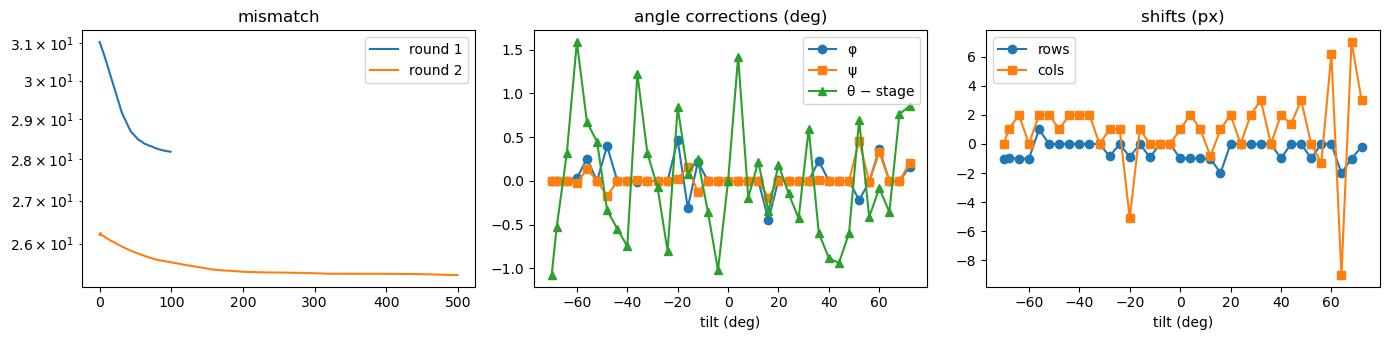

In [9]:
order = np.argsort(angles)
target = th.as_tensor(imgs_rot[order], dtype=th.float32, device=device)
n = len(order)

yy, xx = np.indices((N, N))
tot = imgs_rot[order].sum((1, 2))
com = np.stack([(imgs_rot[order] * yy).sum((1, 2)) / tot, (imgs_rot[order] * xx).sum((1, 2)) / tot])
trans0 = -(com - (N - 1) / 2)                       # (2, n): row shift, column shift in pixels

zeros = np.zeros(n)
theta0 = np.deg2rad(angles[order])

# round 1: shifts only (Alignment_Te.py settings)
(phi1, theta1, psi1, trans1), losses1, _ = align(target, 
    zeros, theta0, zeros, trans0, 30, 100,
    {'phi': False, 'theta': False, 'psi': False, 'translations': True},
    {'phi': {'lr': 1e-4}, 'theta': {'lr': 1e-4}, 'psi': {'lr': 1e-5}, 'translations': {'lr': 1e-2}}, 1e-2)

# round 2: angles and shifts (Alignment_Te.py settings)
(phi_a, theta_a, psi_a, trans_a), losses2, volume = align(target, 
    phi1, theta1, psi1, trans1, 100, 500,
    {'phi': True, 'theta': True, 'psi': True, 'translations': True},
    {'phi': {'lr': 1e-4}, 'theta': {'lr': 1e-4}, 'psi': {'lr': 1e-4}, 'translations': {'lr': 1e-2}}, 1e-5)

fig, axs = plt.subplots(1, 3, figsize=(14, 3.5))
axs[0].semilogy(losses1, label='round 1'); axs[0].semilogy(losses2, label='round 2'); axs[0].legend()
axs[0].set_title('mismatch')
axs[1].plot(angles[order], np.rad2deg(phi_a), 'o-', label='φ'); axs[1].plot(angles[order], np.rad2deg(psi_a), 's-', label='ψ')
axs[1].plot(angles[order], np.rad2deg(theta_a) - angles[order], '^-', label='θ − stage'); axs[1].legend()
axs[1].set_title('angle corrections (deg)')
axs[2].plot(angles[order], trans_a[0], 'o-', label='rows'); axs[2].plot(angles[order], trans_a[1], 's-', label='cols')
axs[2].legend(); axs[2].set_title('shifts (px)')
for ax in axs[1:]:
    ax.set_xlabel('tilt (deg)')
plt.tight_layout(); plt.show()

## 6. Convert and save

The solver and the end-to-end model label the volume's axes differently, and the frames were rotated in step 3. So the angles are converted rather than copied, and the shifts are put in voxels of `dx`. Because of the different labelling, the main tilt ends up in `phi_astra.npy`. Results are saved in your stack order.

In [10]:
def Rx(a): c, s = np.cos(a), np.sin(a); return np.array([[1, 0, 0], [0, c, -s], [0, s, c]])
def Ry(a): c, s = np.cos(a), np.sin(a); return np.array([[c, 0, s], [0, 1, 0], [-s, 0, c]])
def Rz(a): c, s = np.cos(a), np.sin(a); return np.array([[c, -s, 0], [s, c, 0], [0, 0, 1]])

P = np.array([[1, 0, 0], [0, 0, 1], [0, 1, 0]])      # swaps the beam axis between the two conventions
Q = Rz(np.deg2rad(axis_deg))                         # undoes the rotation from step 3
ratio = pixel_binned / (1 / (2 * K_MAX))             # frame pixels -> end-to-end voxels

phi_m, theta_m, psi_m, trans_m = np.zeros(n), np.zeros(n), np.zeros(n), np.zeros((2, n))
for j, i in enumerate(order):                        # j: sorted position, i: position in your stack
    Ra = Rz(phi_a[j]) @ Ry(theta_a[j]) @ Rx(psi_a[j])
    Rm = P @ Ra @ Q.T @ P
    theta_m[i] = -np.arcsin(np.clip(Rm[2, 0], -1, 1))
    phi_m[i] = np.arctan2(Rm[1, 0], Rm[0, 0])
    psi_m[i] = np.arctan2(Rm[2, 1], Rm[2, 2])
    M = np.array([[Ra[0, 0], Ra[1, 0]], [Ra[0, 1], Ra[1, 1]]])
    trans_m[:, i] = np.linalg.solve(M, [trans_a[1, j], trans_a[0, j]]) * ratio

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for name, arr in [('phi', phi_m), ('theta', theta_m), ('psi', psi_m), ('translation', trans_m)]:
    np.save(OUTPUT_DIR / f'{name}_astra.npy', arr.astype(np.float32))
print('saved to', OUTPUT_DIR.resolve())

saved to /dls/e02/data/2026/nt42695-2/processing/Merlin/CeO2_FSP_p2/stacks/alignment_output
